# Descripción del proyecto

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en los aeropuertos. Para atraer a más conductores durante las horas pico, necesitamos predecir la cantidad de pedidos de taxis para la próxima hora. Construye un modelo para dicha predicción.

La métrica RECM en el conjunto de prueba no debe ser superior a 48.

## Instrucciones del proyecto.

1. Descarga los datos y haz el remuestreo por una hora.
2. Analiza los datos
3. Entrena diferentes modelos con diferentes hiperparámetros. La muestra de prueba debe ser el 10% del conjunto de datos inicial.4. Prueba los datos usando la muestra de prueba y proporciona una conclusión.

## Descripción de los datos

Los datos se almacenan en el archivo `taxi.csv`. 	
El número de pedidos está en la columna `num_orders`.

## Preparación

### 1. Lectura y exploración inicial

In [565]:
# Librerías
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

from lightgbm import LGBMRegressor

from statsmodels.tsa.seasonal import seasonal_decompose

import matplotlib.pyplot as plt

In [566]:
# Leer el dataset

df = pd.read_csv('datasets/taxi.csv', parse_dates=[0], index_col=[0])

print(df.shape)
display(df.head())

(26496, 1)


,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [567]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


La columna datetime ya tiene un tipo de dato adecuado, devido al parametro parse_dates al leer el dataset.

### 2. Comprobar que sea secuencial

In [568]:
print(df.index.is_monotonic_increasing)

True


Nuestros serie temporal esta correctamente

### 3. Resampleo

In [569]:
# Hacemos una copia del DataFrame original
df_re = df.copy()

# Resampleamos
df_re = df_re.resample('1h').sum()

df_re.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


Se resampleo por hora con la ayuda del método resample con el argumento 1h y el método sum() que suma los valores dentro del periodo seleccionado.

### 4. Fecha de inicio y fin

In [570]:
print(df_re.index.min())
print(df_re.index.max())

2018-03-01 00:00:00
2018-08-31 23:00:00


Comprobamos la fecha de inicio y final de nuestra serie temporal.

## Análisis

Antes del resampleo por hora

<Axes: xlabel='datetime'>

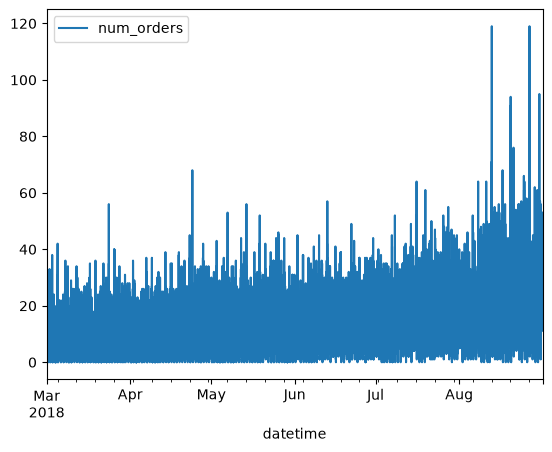

In [571]:
df.plot()

Resampleo por hora

<Axes: xlabel='datetime'>

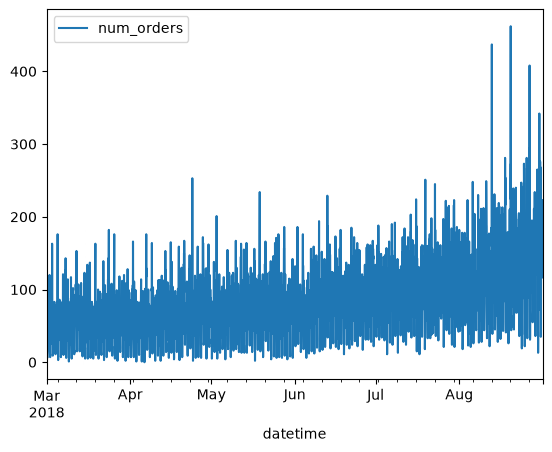

In [572]:
df_re.plot()

**Media móvil**

<Axes: xlabel='datetime'>

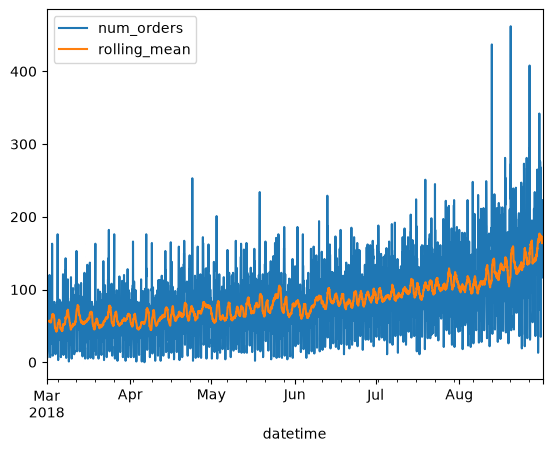

In [573]:
df_re['rolling_mean'] = df_re.rolling(24).mean()
df_re.plot()

**Tendencia y estacionalidad**

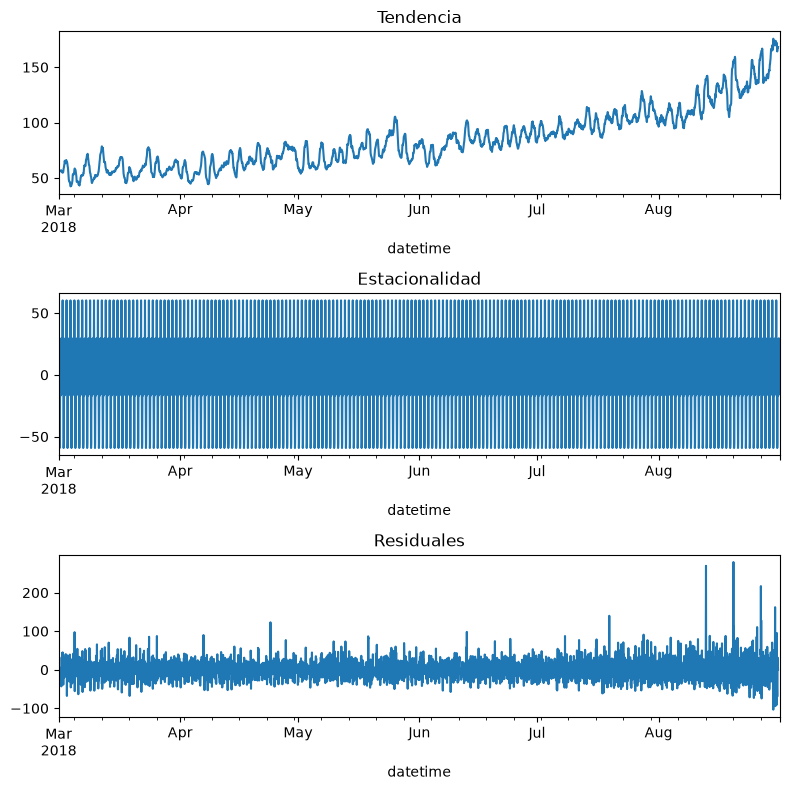

In [574]:
decomposed = seasonal_decompose(df_re['num_orders'])

plt.figure(figsize=(8, 8))
plt.subplot(311)
decomposed.trend.plot(ax=plt.gca())
plt.title('Tendencia')
plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('Estacionalidad')
plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residuales')

plt.tight_layout()

## Formación

In [575]:
# Calcular el RMSE
def calculate_rmse(real, predictions):
    return np.sqrt(mean_squared_error(real, predictions))

### 1. Contruir características

In [576]:
# Función para crear las características
def make_features(data, max_lag, rolling_mean_size):
    """
    Crea features.

    Parametros
    -------------------
    data | DataFrame
        DataFrame del cual se van a obtener las features
    max_lag | int 
        tamaño de desplazamiento
    rolling_mean_size | int
        Tamaño de ventana para calcula la media móvil
    """
    
    data['year'] = data.index.year
    data['month'] = data.index.month
    data['day'] = data.index.day
    data['hour'] = data.index.hour
    data['dayofweek'] = data.index.day_of_week

    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)
    
    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

    return data

print('Función creada exitosamente.')

Función creada exitosamente.


In [577]:
# df_re = make_features(df_re, 6, 10)
# df_re = make_features(df_re, 10, 15)
df_re = make_features(df_re, 12, 17)

df_re.head(15)

,num_orders,rolling_mean,year,month,day,hour,dayofweek,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12
datetime,,,,,,,,,,,,,,,,,,,
2018-03-01 00:00:00,124,NaN,2018,3,1,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 01:00:00,85,NaN,2018,3,1,1,3,124.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 02:00:00,71,NaN,2018,3,1,2,3,85.0,124.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 03:00:00,66,NaN,2018,3,1,3,3,71.0,85.0,124.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 04:00:00,43,NaN,2018,3,1,4,3,66.0,71.0,85.0,124.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 05:00:00,6,NaN,2018,3,1,5,3,43.0,66.0,71.0,85.0,124.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 06:00:00,12,NaN,2018,3,1,6,3,6.0,43.0,66.0,71.0,85.0,124.0,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 07:00:00,15,NaN,2018,3,1,7,3,12.0,6.0,43.0,66.0,71.0,85.0,124.0,NaN,NaN,NaN,NaN,NaN
2018-03-01 08:00:00,34,NaN,2018,3,1,8,3,15.0,12.0,6.0,43.0,66.0,71.0,85.0,124.0,NaN,NaN,NaN,NaN


Se contrulleron las características con una diferencia de series temporales de 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12 y una media móvil de 17 horas.

### 2. Conjunto de entrenamiento y prueba

In [578]:
# Dividir dataset en conjunto de entrenamiento y validación

train, test = train_test_split(df_re, shuffle=False, test_size=0.1, random_state=42)

# Desacernos de los nulos
train = train.dropna()

# Obtener las características y el objetivo
train_features = train.drop('num_orders', axis=1)
train_target = train['num_orders']
test_features = test.drop('num_orders', axis=1)
test_target = test['num_orders']

print(train_features.shape)
print(train_target.shape)
print(test_features.shape)
print(test_target.shape)

(3957, 18)
(3957,)
(442, 18)
(442,)


Se separa en conjunto de entrenamiento y validación. También se eliminaron los nulos ya que al calcular la media móvil y el desplazamiento en los primeros registros como no tiene su respectivo registro quedan en nulo.

### 3. Conjunto de validación

In [579]:
train_features, valid_features, train_target, valid_target = train_test_split(
    train_features,
    train_target,
    shuffle=False,
    test_size=0.1,
    random_state=42
)

print('conjunto de validación creado exitosamente.')

conjunto de validación creado exitosamente.


También se requirio de un conjunto de validación para calcular el rmse durante el entrenamiento de los modelos.

### 4. Función para entrenar y evaluar modelos

In [580]:
# Función para entrenar y evaluar el modelo
def train_and_evaluate(
        name,
        model,
        train_features=train_features,
        train_target=train_target,
        valid_features=valid_features,
        valid_target=valid_target):

    """
    Entreanr un modelo dentro de un Pipeline y calcular métrica RMSE.

    Parametros
    -------------
    name : str
        Nombre del modelo
    modelo : modelo
        Modelo que queremos probar
    train_features, train_target, valid_features, valid_target : pandas DataFrame / Series
        Datos ya separados en entrenamiento y validación.
    """

    pipeline = Pipeline(steps=[
        ('model', model)
    ])

    pipeline.fit(train_features, train_target)

    predictions = pipeline.predict(valid_features)

    rmse = calculate_rmse(valid_target, predictions)

    results = {
        'model': name,
        'rmse': rmse,
        'pipeline': pipeline
    }

    return results

print('Función creado exitosamente.')

Función creado exitosamente.


### 3. Modelo Base: Regresión Lineal 

In [581]:
# Entrenando modelo base: regresión lineal
lr_result = train_and_evaluate(
    name='Regresión Lineal',
    model=LinearRegression()
)

lr_rmse = {k: v for k, v in lr_result.items() if k != 'pipeline'}
pd.DataFrame([lr_rmse])

,model,rmse
0,Regresión Lineal,40.017425


Se entreno una regresión lineal como modelo base.

### 4. Bosque aleatorio

In [582]:
forest_results = []

for n_estimators in range(40, 61, 5):
    for max_depth in range(6, 13, 2):
        result = train_and_evaluate(
            name=f'Bosque Aleatorio n_estimators={n_estimators} max_depth={max_depth}',
            model=RandomForestRegressor(
                n_estimators=n_estimators,
                max_depth=max_depth,
                random_state=42
            )
        )
        
        forest_results.append(result)

forest_summary = pd.DataFrame([
    {k: v for k, v in r.items() if k!= 'pipeline'}
    for r in forest_results
])

display(forest_summary)

,model,rmse
0,Bosque Aleatorio n_estimators=40 max_depth=6,34.575354
1,Bosque Aleatorio n_estimators=40 max_depth=8,32.447321
2,Bosque Aleatorio n_estimators=40 max_depth=10,31.395268
3,Bosque Aleatorio n_estimators=40 max_depth=12,31.018108
4,Bosque Aleatorio n_estimators=45 max_depth=6,34.597669
5,Bosque Aleatorio n_estimators=45 max_depth=8,32.379987
6,Bosque Aleatorio n_estimators=45 max_depth=10,31.293509
7,Bosque Aleatorio n_estimators=45 max_depth=12,30.956465
8,Bosque Aleatorio n_estimators=50 max_depth=6,34.577655
9,Bosque Aleatorio n_estimators=50 max_depth=8,32.454958


Se entreno un Bosque Aleatorio probando con diferentes valores para los parametros n_estimators y max_depth.

### 4. LightGBM

In [583]:
lightgbm_results = []

lightgbm_settings = [
    {'n_estimators': 10, 'max_depth': 4},
    {'n_estimators': 20, 'max_depth': 6},
    {'n_estimators': 30, 'max_depth': 6},
    {'n_estimators': 50, 'max_depth': 6},
    {'n_estimators': 100, 'max_depth': 8},
    {'n_estimators': 150, 'max_depth': 10},
    {'n_estimators': 200, 'max_depth': 12},
]

for config in lightgbm_settings:
    result = train_and_evaluate(
        name='LightGBM Regressor',
        model=LGBMRegressor(
            n_estimators=config['n_estimators'],
            max_depth=config['max_depth'],
            verbose=-1,
            random_state=42,   
        ),
    )

    lightgbm_results.append(result)

lightgbm_summary = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'pipeline'}
    for r in lightgbm_results
])

display(lightgbm_summary)

,model,rmse
0,LightGBM Regressor,44.361523
1,LightGBM Regressor,34.133349
2,LightGBM Regressor,32.597891
3,LightGBM Regressor,31.441039
4,LightGBM Regressor,31.404053
5,LightGBM Regressor,31.149565
6,LightGBM Regressor,31.089976


También se entrenaron modelos de LightGBM con diferentes valores para los hiperperametros n_estimators y max_depth.

## Prueba

In [584]:
results = [
    lr_result,
    *forest_results,
    *lightgbm_results
]

comparison = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'pipeline'}
    for r in results
]).sort_values('rmse')

display(comparison)

,model,rmse
8,Bosque Aleatorio n_estimators=45 max_depth=12,30.956465
4,Bosque Aleatorio n_estimators=40 max_depth=12,31.018108
20,Bosque Aleatorio n_estimators=60 max_depth=12,31.033494
12,Bosque Aleatorio n_estimators=50 max_depth=12,31.084967
27,LightGBM Regressor,31.089976
16,Bosque Aleatorio n_estimators=55 max_depth=12,31.133680
26,LightGBM Regressor,31.149565
7,Bosque Aleatorio n_estimators=45 max_depth=10,31.293509
19,Bosque Aleatorio n_estimators=60 max_depth=10,31.387254
11,Bosque Aleatorio n_estimators=50 max_depth=10,31.388298


Tabla comparativa de RECM.

### 1. Prueba final

Modelo seleccionado para la prueba: RandomForestRegressor

In [585]:
# Obteniendo el mejor modelo
best_model = forest_results[7]['pipeline']

predictions = best_model.predict(test_features)

rmse = calculate_rmse(test_target, predictions)

print('RMSE con el conjunto de prueba: ', rmse)

RMSE con el conjunto de prueba:  47.848098576557845


In [586]:
print('Conclusión final')
print()
print(
    f"Se entrenaron diferentes modelos con diferentes parametros en el cual se logro obtener un rmse por debajo de 48.",
    f"Fue alcanzado por el modelo con los siguientes parametros: {forest_results[7]['model']}. ",
    f"La raiz cuadrada del error medio en el conjunto de entrenamiento fue de {rmse}."


)

Conclusión final

Se entrenaron diferentes modelos con diferentes parametros en el cual se logro obtener un rmse por debajo de 48. Fue alcanzado por el modelo con los siguientes parametros: Bosque Aleatorio n_estimators=45 max_depth=12.  La raiz cuadrada del error medio en el conjunto de entrenamiento fue de 47.848098576557845.


Depués de entrenar diferentes modelos, se selecciono el modelo final únicamente tomando el mejor modelo de la tabla comparativa. El cual al probarla con el conjunto de prueba se obtiene un RECM menor 48 (requerido por la compañía Sweet Lift Taxi).

# Lista de revisión

- [x]  	
Jupyter Notebook está abierto.
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución.
- [x]  	
Los datos han sido descargados y preparados.
- [x]  Se ha realizado el paso 2: los datos han sido analizados
- [x]  Se entrenó el modelo y se seleccionaron los hiperparámetros
- [x]  Se han evaluado los modelos. Se expuso una conclusión
- [x] La *RECM* para el conjunto de prueba no es más de 48